# 03 — Channel Analysis

## Objective
This notebook examines the two EMG channels to explore their signal characteristics and compare muscle activity during squatting.

## Workflow
1. Load and inspect the EMG channel data.
2. Examine the channel signals using visualisation.
3. Compare the observed signal characteristics between channels.

## Interpretation note
Differences between the channel signals are exploratory and should not be interpreted as clinically validated evidence of muscle imbalance.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Channel_1  Channel_2
0  -0.008141  -0.218128
1  -0.043554  -0.142946
2  -0.035050  -0.180434
3  -0.044853   0.002266
4  -0.049953   0.136480


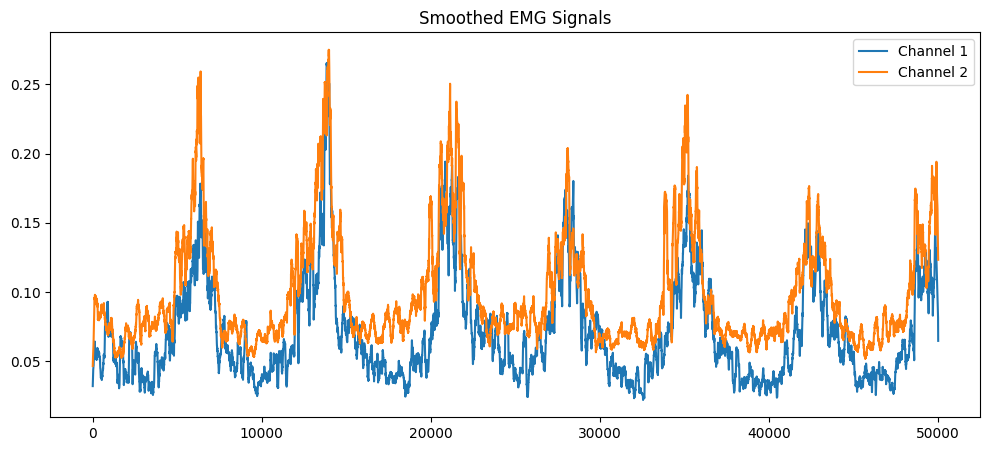

Mean activation:
Channel 1: 0.07067730606854405
Channel 2: 0.09881261376929722
Max activation:
Channel 1: 0.2655380299435338
Channel 2: 0.2749112679428917
Activation index:
Channel 1: 58
Channel 2: 8


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# Step 1: Mount drive
drive.mount('/content/drive')

# Step 2: LOAD your CSV (THIS WAS MISSING)
file_name = "/content/drive/MyDrive/emg_final.csv"
df = pd.read_csv(file_name)

print(df.head())

# Step 3: Smooth signals
def smooth(signal, window=200):
    return np.convolve(signal, np.ones(window)/window, mode='same')

df['S1'] = smooth(np.abs(df['Channel_1']))
df['S2'] = smooth(np.abs(df['Channel_2']))

# Step 4: Plot
plt.figure(figsize=(12,5))
plt.plot(df['S1'], label='Channel 1')
plt.plot(df['S2'], label='Channel 2')
plt.legend()
plt.title("Smoothed EMG Signals")
plt.show()

# Step 5: Stats
print("Mean activation:")
print("Channel 1:", df['S1'].mean())
print("Channel 2:", df['S2'].mean())

print("Max activation:")
print("Channel 1:", df['S1'].max())
print("Channel 2:", df['S2'].max())

# Step 6: Activation timing
threshold = 0.05

t1 = np.argmax(df['S1'] > threshold)
t2 = np.argmax(df['S2'] > threshold)

print("Activation index:")
print("Channel 1:", t1)
print("Channel 2:", t2)
